<a href="https://colab.research.google.com/github/Srinjoyee2006/APP-Projects/blob/main/Social_Media_Topic_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Social Media Topic Clustering

**Problem Statement:** Social media posts often form latent topic clusters. This project applies Gaussian Mixture Models and Hierarchical Clustering to group posts, evaluates dissimilarity metrics, and compares clustering outputs.

**Objective:** To discover hidden topics in social media posts using unsupervised machine learning and compare the performance of different clustering techniques.

In [15]:
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = (
    "https://huggingface.co/datasets/cardiffnlp/"
    "tweet_topic_multi/resolve/"
    "dc65379cfc7721f579c97656a1ebdbb80aedad08/"
    "tweet_topic_multi/train_all-00000-of-00001.parquet"
)

os.makedirs("data", exist_ok=True)

file_path = "data/tweet_topic.parquet"

urllib.request.urlretrieve(url, file_path)

print("Dataset downloaded successfully!")
print("File size:", round(os.path.getsize(file_path) / 1024, 2), "KB")

Dataset downloaded successfully!
File size: 851.76 KB


This cell downloads the TweetTopic dataset from Hugging Face and saves it in the Colab environment in Parquet format. Parquet is a tabular data format that preserves text and label columns efficiently. The source notebook identifies this file as containing 6,090 tweets.

In [16]:
df = pd.read_parquet(file_path)

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nFirst 5 Records:")
display(df.head())

Dataset Shape: (6090, 5)

Column Names:
['text', 'date', 'label', 'label_name', 'id']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6090 entries, 0 to 6089
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   text        6090 non-null   object
 1   date        6090 non-null   object
 2   label       6090 non-null   object
 3   label_name  6090 non-null   object
 4   id          6090 non-null   object
dtypes: object(5)
memory usage: 238.0+ KB

First 5 Records:


,text,date,label,label_name,id
0,The {@Clinton LumberKings@} beat the {@Cedar R...,2019-09-08,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",[sports],1170516324419866624
1,I would rather hear Eli Gold announce this Aub...,2019-09-08,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",[sports],1170516440690176006
2,"Someone take my phone away, I’m trying to not ...",2019-09-08,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",[sports],1170516543387709440
3,"A year ago, Louisville struggled to beat an FC...",2019-09-08,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",[sports],1170516620466429953
4,Anyone know why the #Dodgers #Orioles game nex...,2019-09-08,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, ...",[sports],1170516711411310592


This cell loads the downloaded file into a pandas DataFrame. We inspect the number of rows, columns, data types, and sample records to understand the structure before preprocessing.

In [17]:
print("Missing Values:")
print(df.isnull().sum())

# Check duplicate tweets using the text column
print("\nDuplicate Posts:", df['text'].duplicated().sum())

print("\nAvailable Columns:")
print(df.columns.tolist())

# Display topic label distribution
if "label_name" in df.columns:
    topic_labels = df.explode("label_name")

    print("\nTopic Label Distribution:")
    display(
        topic_labels["label_name"]
        .value_counts()
        .to_frame("Post Count")
    )

Missing Values:
text          0
date          0
label         0
label_name    0
id            0
dtype: int64

Duplicate Posts: 0

Available Columns:
['text', 'date', 'label', 'label_name', 'id']

Topic Label Distribution:


,Post Count
label_name,
news_&_social_concern,1782
sports,1683
music,1131
film_tv_&_video,953
celebrity_&_pop_culture,924
diaries_&_daily_life,866
arts_&_culture,298
science_&_technology,294
business_&_entrepreneurs,288


This step checks for missing values and duplicate posts using the text column. Since the label columns contain NumPy arrays, checking duplicates across the entire DataFrame causes a TypeError. We therefore check duplicates using the tweet text alone. The topic label distribution shows how frequently each topic occurs in the dataset.

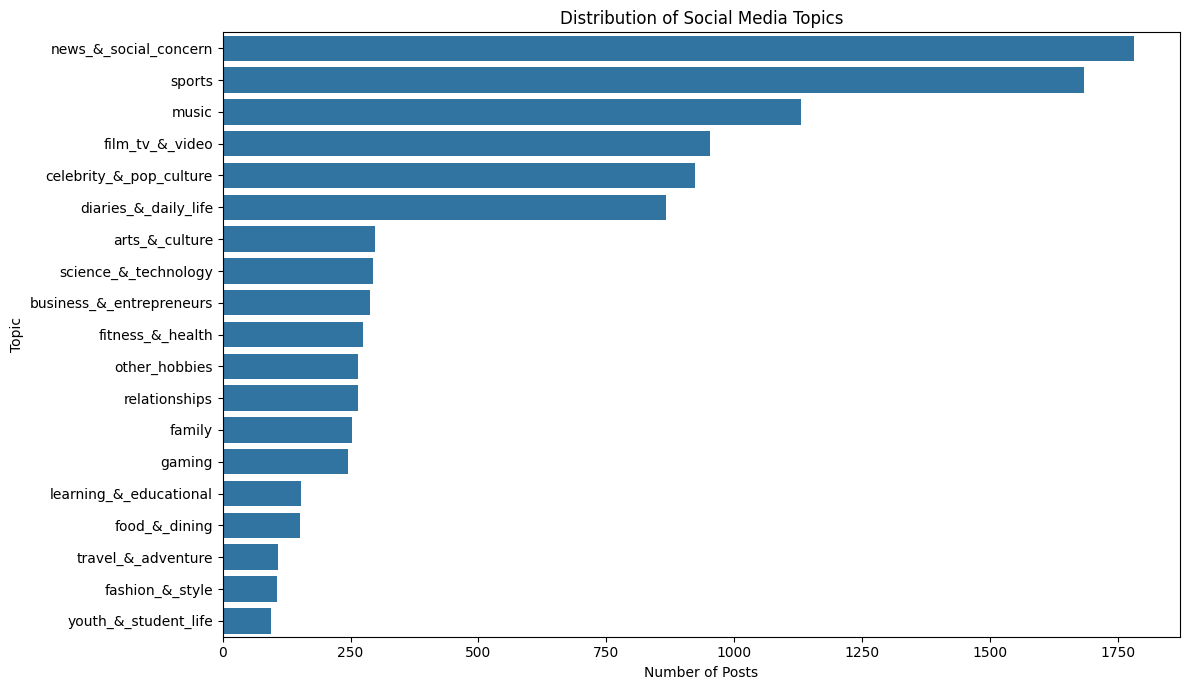

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

topic_counts = (
    df.explode('label_name')['label_name']
      .value_counts()
      .sort_values(ascending=False)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=topic_counts.values,
    y=topic_counts.index
)

plt.title('Distribution of Social Media Topics')
plt.xlabel('Number of Posts')
plt.ylabel('Topic')
plt.tight_layout()
plt.show()

This bar chart displays the frequency of each topic in the dataset. It helps us identify popular topics and understand whether the dataset has an imbalanced topic distribution.

Post Length Statistics:


,Post_Length
count,6090.000000
mean,170.227258
std,68.836066
min,38.000000
25%,110.000000
50%,161.500000
75%,230.000000
max,364.000000


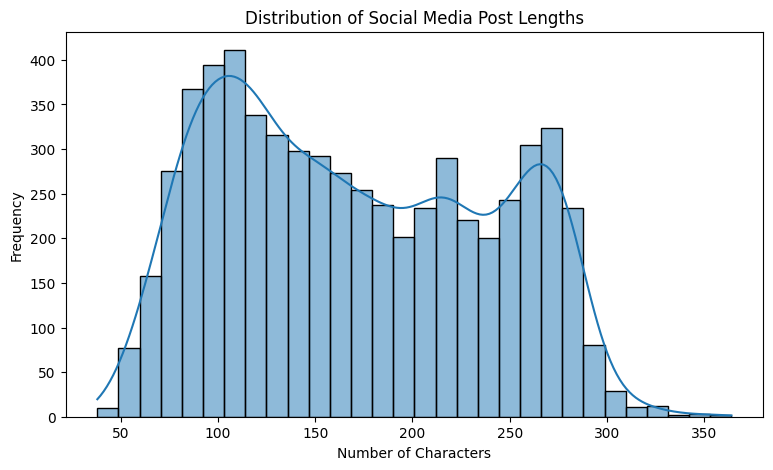

In [19]:
df['Post_Length'] = df['text'].astype(str).str.len()

print("Post Length Statistics:")
display(df['Post_Length'].describe())

plt.figure(figsize=(9, 5))

sns.histplot(df['Post_Length'], bins=30, kde=True)

plt.title('Distribution of Social Media Post Lengths')
plt.xlabel('Number of Characters')
plt.ylabel('Frequency')
plt.show()

This step calculates the length of each post and visualizes the distribution. Understanding post lengths helps us identify unusually short or long posts before text preprocessing.

In [20]:
import re

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'#', '', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

df['clean_text'] = df['text'].apply(clean_text)

print("Original Post:")
print(df['text'].iloc[0])

print("\nCleaned Post:")
print(df['clean_text'].iloc[0])

Original Post:
The {@Clinton LumberKings@} beat the {@Cedar Rapids Kernels@} 4-0 in Game 1 of the Western Division finals. Evan Edwards hit a 2-run HR. WP Josh Roberson: 5 IP, 3 H, 0 R, 0 BB, 10 K #MWLplayoffs #MWLscoreboard

Cleaned Post:
the lumberkings beat the rapids kernels in game of the western division finals evan edwards hit a run hr wp josh roberson ip h r bb k mwlplayoffs mwlscoreboard


Text cleaning converts posts to lowercase and removes URLs, user mentions, hashtag symbols, punctuation, and extra whitespace. The cleaned text provides a more consistent input for numerical text representation.

In [21]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer(
    stop_words='english',
    max_features=3000,
    min_df=2,
    max_df=0.95,
    ngram_range=(1, 2)
)

X_tfidf = vectorizer.fit_transform(df['clean_text'])

print("Number of Posts:", X_tfidf.shape[0])
print("Number of Features:", X_tfidf.shape[1])

print("\nSample Vocabulary:")
print(vectorizer.get_feature_names_out()[:30])

Number of Posts: 6090
Number of Features: 3000

Sample Vocabulary:
['aag' 'aaron' 'aaron hernandez' 'abc' 'ability' 'able' 'absolute'
 'absolutely' 'absolutely love' 'abuse' 'academy' 'accept' 'access'
 'according' 'account' 'act' 'acting' 'action' 'actions' 'active'
 'activity' 'actor' 'actually' 'ad' 'adams' 'add' 'added' 'added closet'
 'addition' 'address']


TF-IDF converts text into numerical feature vectors based on word importance. Common English stop words are removed, and the feature limit controls memory usage. These numerical vectors will be used as the input to our clustering algorithms.

In [22]:
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

svd = TruncatedSVD(
    n_components=100,
    random_state=42
)

X_reduced = svd.fit_transform(X_tfidf)

# Normalize the reduced feature vectors
X_reduced = normalize(X_reduced)

print("Original TF-IDF Shape:", X_tfidf.shape)
print("Reduced Feature Shape:", X_reduced.shape)

print(
    "Explained Variance Ratio:",
    round(svd.explained_variance_ratio_.sum(), 4)
)

Original TF-IDF Shape: (6090, 3000)
Reduced Feature Shape: (6090, 100)
Explained Variance Ratio: 0.2341


Truncated Singular Value Decomposition (SVD) reduces the high-dimensional TF-IDF representation to 100 numerical components. This makes clustering more computationally manageable while preserving important patterns in the text. Normalization scales the resulting feature vectors to unit length.

In [23]:
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score

cluster_options = [4, 6, 8, 10, 12]
silhouette_scores = []

for k in cluster_options:
    gmm = GaussianMixture(
        n_components=k,
        covariance_type='diag',
        random_state=42,
        n_init=2,
        reg_covar=1e-5
    )

    labels = gmm.fit_predict(X_reduced)

    score = silhouette_score(
        X_reduced,
        labels,
        sample_size=min(2000, len(X_reduced)),
        random_state=42
    )

    silhouette_scores.append(score)

    print(f"Clusters: {k}, Silhouette Score: {score:.4f}")

Clusters: 4, Silhouette Score: 0.0097
Clusters: 6, Silhouette Score: 0.0061
Clusters: 8, Silhouette Score: -0.0007
Clusters: 10, Silhouette Score: 0.0074
Clusters: 12, Silhouette Score: 0.0285


This experiment fits Gaussian Mixture Models with different numbers of components. We calculate the Silhouette Score on a reproducible sample to reduce computation time. The results help us choose a candidate cluster count, although the highest score alone does not guarantee the most meaningful topics.

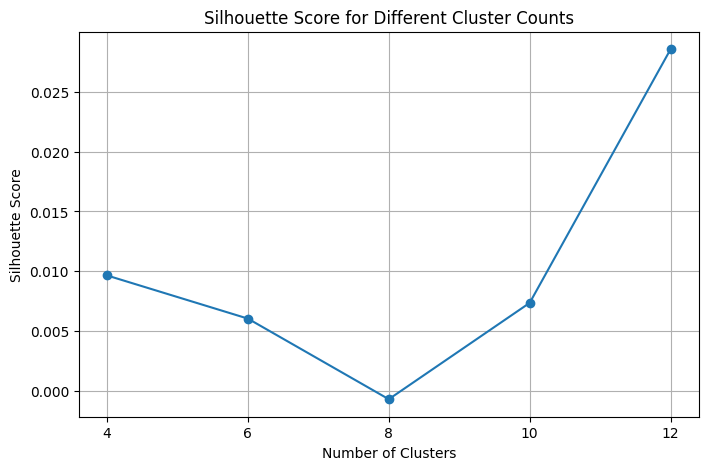

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(
    cluster_options,
    silhouette_scores,
    marker='o'
)

plt.title('Silhouette Score for Different Cluster Counts')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.xticks(cluster_options)
plt.grid(True)
plt.show()

This line graph compares clustering quality across different values of \(k\). We can identify which candidate cluster count provides the strongest separation according to the Silhouette Score.

In [25]:
from sklearn.mixture import GaussianMixture

n_clusters = 12

gmm = GaussianMixture(
    n_components=n_clusters,
    covariance_type='diag',
    random_state=42,
    n_init=3,
    reg_covar=1e-5
)

df['GMM_Cluster'] = gmm.fit_predict(X_reduced)

print("GMM Clustering Completed!")

print("\nCluster Distribution:")
print(df['GMM_Cluster'].value_counts().sort_index())

print("\nSample Results:")
display(df[['text', 'label_name', 'GMM_Cluster']].head(10))

GMM Clustering Completed!

Cluster Distribution:
GMM_Cluster
0      764
1     1176
2      649
3      377
4      932
5      213
6      148
7      131
8      187
9      663
10     582
11     268
Name: count, dtype: int64

Sample Results:


,text,label_name,GMM_Cluster
0,The {@Clinton LumberKings@} beat the {@Cedar R...,[sports],11
1,I would rather hear Eli Gold announce this Aub...,[sports],11
2,"Someone take my phone away, I’m trying to not ...",[sports],11
3,"A year ago, Louisville struggled to beat an FC...",[sports],11
4,Anyone know why the #Dodgers #Orioles game nex...,[sports],11
5,"I don’t care. you gave him a shot, he is strug...",[sports],11
6,Okay how can I watch the {@Arkansas State Foot...,[sports],11
7,Check out largest crowds ever for a basketball...,[sports],9
8,I voted #WeWantNCAAFootball on {{USERNAME}} . ...,"[gaming, sports]",11
9,Streaming a new game #minionmasters come stop ...,[gaming],10


Gaussian Mixture Model represents the posts as a mixture of Gaussian distributions. Each post is assigned to the component with the highest estimated membership probability. The cluster distribution shows how many posts were assigned to each group.

In [26]:
from sklearn.cluster import AgglomerativeClustering

hierarchical = AgglomerativeClustering(
    n_clusters=12,
    linkage='ward'
)

df['Hierarchical_Cluster'] = hierarchical.fit_predict(X_reduced)

print("Hierarchical Clustering Completed!")

print("\nCluster Distribution:")
print(
    df['Hierarchical_Cluster']
    .value_counts()
    .sort_index()
)

print("\nSample Results:")
display(
    df[['text', 'label_name', 'Hierarchical_Cluster']].head(10)
)

Hierarchical Clustering Completed!

Cluster Distribution:
Hierarchical_Cluster
0     3907
1      403
2      451
3      286
4      261
5      177
6      155
7      110
8       90
9       83
10      64
11     103
Name: count, dtype: int64

Sample Results:


,text,label_name,Hierarchical_Cluster
0,The {@Clinton LumberKings@} beat the {@Cedar R...,[sports],0
1,I would rather hear Eli Gold announce this Aub...,[sports],0
2,"Someone take my phone away, I’m trying to not ...",[sports],0
3,"A year ago, Louisville struggled to beat an FC...",[sports],0
4,Anyone know why the #Dodgers #Orioles game nex...,[sports],0
5,"I don’t care. you gave him a shot, he is strug...",[sports],0
6,Okay how can I watch the {@Arkansas State Foot...,[sports],0
7,Check out largest crowds ever for a basketball...,[sports],0
8,I voted #WeWantNCAAFootball on {{USERNAME}} . ...,"[gaming, sports]",0
9,Streaming a new game #minionmasters come stop ...,[gaming],0


Agglomerative Clustering begins with individual posts and repeatedly merges similar groups until 12 clusters remain. Ward linkage uses Euclidean distance to determine which merges minimize the increase in cluster variance.

In [27]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)

cluster_results = {
    'Gaussian Mixture Model': df['GMM_Cluster'].values,
    'Hierarchical Clustering': df['Hierarchical_Cluster'].values
}

results = []

for name, labels in cluster_results.items():
    results.append({
        'Algorithm': name,
        'Silhouette Score': silhouette_score(
            X_reduced, labels,
            sample_size=min(2000, len(df)),
            random_state=42
        ),
        'Davies-Bouldin Index': davies_bouldin_score(
            X_reduced, labels
        ),
        'Calinski-Harabasz Score': calinski_harabasz_score(
            X_reduced, labels
        ),
        'Adjusted Rand Index': adjusted_rand_score(
            df['label_name'].astype(str), labels
        )
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score,Adjusted Rand Index
0,Gaussian Mixture Model,0.0134,5.3073,56.7727,0.0329
1,Hierarchical Clustering,0.0306,2.9939,77.0672,0.0397


This step evaluates both algorithms using internal clustering metrics and an external comparison metric. Higher Silhouette and Calinski–Harabasz scores are generally preferable, while a lower Davies–Bouldin Index is generally preferable. The Adjusted Rand Index compares discovered clusters with the reference labels

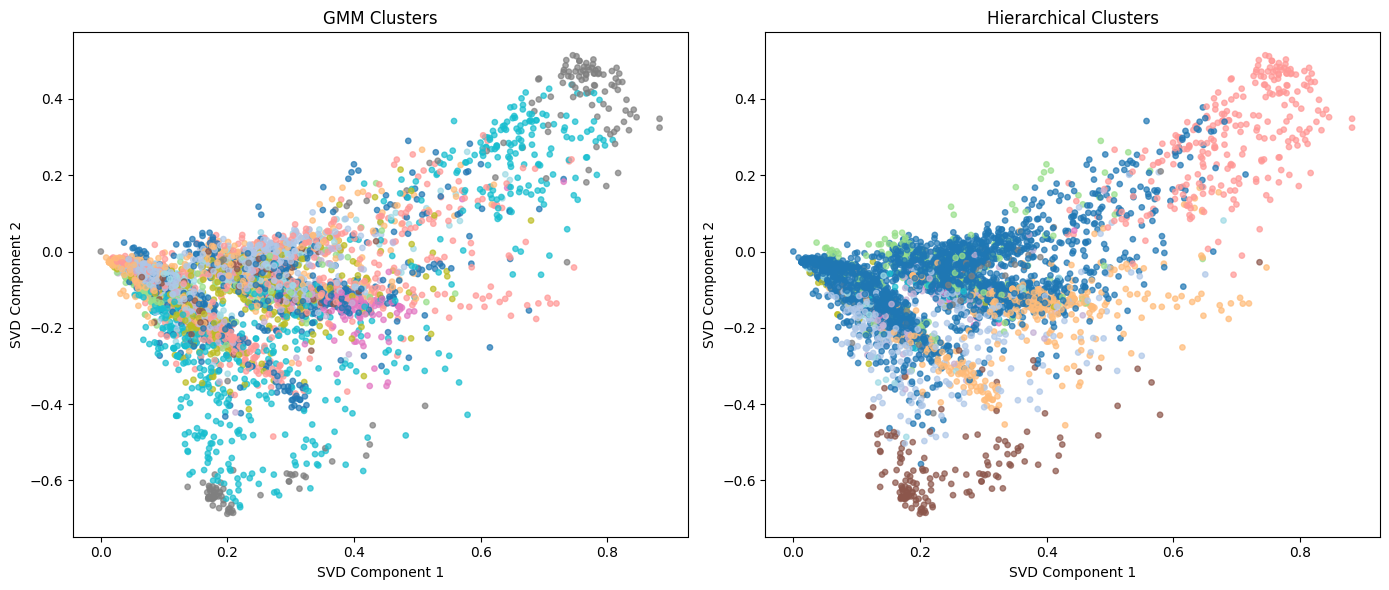

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].scatter(
    X_reduced[:, 0],
    X_reduced[:, 1],
    c=df['GMM_Cluster'],
    cmap='tab20',
    s=15,
    alpha=0.7
)
axes[0].set_title('GMM Clusters')
axes[0].set_xlabel('SVD Component 1')
axes[0].set_ylabel('SVD Component 2')

axes[1].scatter(
    X_reduced[:, 0],
    X_reduced[:, 1],
    c=df['Hierarchical_Cluster'],
    cmap='tab20',
    s=15,
    alpha=0.7
)
axes[1].set_title('Hierarchical Clusters')
axes[1].set_xlabel('SVD Component 1')
axes[1].set_ylabel('SVD Component 2')

plt.tight_layout()
plt.show()

These scatter plots show the cluster assignments from both algorithms using the first two reduced dimensions. Since the clustering was performed in 100 dimensions, the plots are only a simplified visual projection and may not show the complete separation between clusters.

In [29]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    pairwise_distances,
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Use a reproducible subset to keep distance calculations manageable
sample_size = min(2000, len(X_reduced))

rng = np.random.RandomState(42)
sample_indices = rng.choice(
    len(X_reduced),
    size=sample_size,
    replace=False
)

X_sample = X_reduced[sample_indices]

# Calculate Euclidean and cosine dissimilarity matrices
euclidean_distances = pairwise_distances(
    X_sample,
    metric='euclidean'
)

cosine_distances = pairwise_distances(
    X_sample,
    metric='cosine'
)

# Hierarchical clustering using average linkage
euclidean_model = AgglomerativeClustering(
    n_clusters=12,
    metric='precomputed',
    linkage='average'
)

cosine_model = AgglomerativeClustering(
    n_clusters=12,
    metric='precomputed',
    linkage='average'
)

euclidean_labels = euclidean_model.fit_predict(
    euclidean_distances
)

cosine_labels = cosine_model.fit_predict(
    cosine_distances
)

metric_results = []

for name, distances, labels in [
    ('Euclidean', euclidean_distances, euclidean_labels),
    ('Cosine', cosine_distances, cosine_labels)
]:
    metric_results.append({
        'Dissimilarity Metric': name,
        'Silhouette Score': silhouette_score(
            distances, labels, metric='precomputed'
        ),
        'Davies-Bouldin Index': davies_bouldin_score(
            X_sample, labels
        ),
        'Calinski-Harabasz Score': calinski_harabasz_score(
            X_sample, labels
        )
    })

metric_results_df = pd.DataFrame(metric_results)

display(metric_results_df.round(4))

,Dissimilarity Metric,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,Euclidean,0.0408,2.5738,18.0452
1,Cosine,0.0560,2.6229,17.7891


This experiment compares Euclidean and cosine dissimilarity using the same sample of posts and the same number of clusters. Euclidean distance measures geometric separation, while cosine distance measures the difference in vector direction. Average linkage supports both distance metrics.

In [30]:
terms = vectorizer.get_feature_names_out()

def display_cluster_topics(cluster_column, n_terms=10):
    for cluster_id in sorted(df[cluster_column].unique()):
        indices = np.where(
            df[cluster_column].values == cluster_id
        )[0]

        mean_tfidf = np.asarray(
            X_tfidf[indices].mean(axis=0)
        ).ravel()

        top_indices = mean_tfidf.argsort()[-n_terms:][::-1]
        top_terms = terms[top_indices]

        print(f"\nCluster {cluster_id}")
        print("Top terms:", ", ".join(top_terms))

        print("Example posts:")
        for post in df.iloc[indices[:2]]['text']:
            print("-", post[:200].replace('\n', ' '))

display_cluster_topics('GMM_Cluster')


Cluster 0
Top terms: username, love, happy, url, day, easter, username url, eid, jesus, family
Example posts:
- Girard Indians vs John F Kennedy Eagles {{USERNAME}} {{URL}} #HSBOH_W3R13
- I still want the original #Charmed to come back! {{USERNAME}} {@Holly Marie Combs Ryan@} {@Shannen Doherty@} {@Rose McGowan@} ! #Streghe #Ilpoteredeltriocoincidecolmio #ThePowerofThreewillsetusFree {@

Cluster 1
Top terms: username, url, don, remember, make, great, team, today, people, man
Example posts:
- I loved every minute of {@Harry Smith@} vs {@FILTHY@} That definitely became one of my favorite pro-wrestling matches I ve ever seen in my life!!!!!! #Bloodsport
- Anyone wants an example of someone bigger than the sport? M. S. #Dhoni. To quote {@ESPNcricinfo@} : Dhoni is not retired. Or injured. He is not rested. Nobody dares utter the word  dropped .

Cluster 2
Top terms: username, url, th, world, stay, bad, time, super, bowl, super bowl
Example posts:
- Shout out to {{USERNAME}} for giving my 6 

This function calculates average TF-IDF weights for each cluster and lists its most representative terms and example posts. The terms help us interpret the underlying topics without relying solely on the original labels.

In [31]:
import re

def clean_text_v2(text):
    text = str(text).lower()

    # Remove social media placeholders before general cleaning
    text = re.sub(r'\{\{.*?\}\}', ' ', text)
    text = re.sub(r'\{@.*?@\}', ' ', text)

    # Remove URLs and user mentions
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'@\w+', ' ', text)

    # Remove hashtag symbol while preserving the hashtag word
    text = re.sub(r'#', '', text)

    # Keep alphabetic words only
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text)

    return text.strip()


df['clean_text_v2'] = df['text'].apply(clean_text_v2)

print("Original:")
print(df['text'].iloc[0])

print("\nImproved cleaned text:")
print(df['clean_text_v2'].iloc[0])

Original:
The {@Clinton LumberKings@} beat the {@Cedar Rapids Kernels@} 4-0 in Game 1 of the Western Division finals. Evan Edwards hit a 2-run HR. WP Josh Roberson: 5 IP, 3 H, 0 R, 0 BB, 10 K #MWLplayoffs #MWLscoreboard

Improved cleaned text:
the beat the in game of the western division finals evan edwards hit a run hr wp josh roberson ip h r bb k mwlplayoffs mwlscoreboard


This function removes annotated entity placeholders, URLs, and user mentions before extracting meaningful words. Hashtag words are retained because they may provide useful topic information.

In [32]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer_v2 = TfidfVectorizer(
    stop_words='english',
    max_features=3000,
    min_df=2,
    max_df=0.90,
    ngram_range=(1, 2),
    sublinear_tf=True
)

X_tfidf_v2 = vectorizer_v2.fit_transform(df['clean_text_v2'])

print("Updated TF-IDF Matrix:", X_tfidf_v2.shape)
print("\nSample Vocabulary:")
print(vectorizer_v2.get_feature_names_out()[:40])

Updated TF-IDF Matrix: (6090, 3000)

Sample Vocabulary:
['aag' 'aaron' 'aaron hernandez' 'abc' 'ability' 'able' 'absolute'
 'absolutely' 'absolutely love' 'abuse' 'academy' 'accept' 'access'
 'according' 'account' 'accountable' 'act' 'acting' 'action' 'actions'
 'active' 'activist' 'activity' 'actor' 'actually' 'ad' 'adams' 'add'
 'added' 'added closet' 'addition' 'address' 'administration' 'advance'
 'adventure' 'advice' 'af' 'affected' 'africa' 'african']


The TF-IDF representation is rebuilt using the improved text. This reduces the influence of repeated placeholder tokens and gives more capacity to words that describe the actual subject of each post

In [33]:
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

svd_v2 = TruncatedSVD(
    n_components=100,
    random_state=42
)

X_reduced_v2 = svd_v2.fit_transform(X_tfidf_v2)
X_reduced_v2 = normalize(X_reduced_v2)

print("Reduced Shape:", X_reduced_v2.shape)
print(
    "Explained Variance Ratio:",
    round(svd_v2.explained_variance_ratio_.sum(), 4)
)

Reduced Shape: (6090, 100)
Explained Variance Ratio: 0.2242


Truncated SVD compresses the improved TF-IDF features into 100 dimensions. These new features will be used for the final clustering experiment.

In [34]:
from sklearn.mixture import GaussianMixture
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# GMM
gmm_v2 = GaussianMixture(
    n_components=12,
    covariance_type='diag',
    random_state=42,
    n_init=3,
    reg_covar=1e-5
)

gmm_labels_v2 = gmm_v2.fit_predict(X_reduced_v2)

# Hierarchical clustering
hierarchical_v2 = AgglomerativeClustering(
    n_clusters=12,
    linkage='ward'
)

hierarchical_labels_v2 = hierarchical_v2.fit_predict(
    X_reduced_v2
)

final_results = []

for name, labels in [
    ('GMM', gmm_labels_v2),
    ('Hierarchical', hierarchical_labels_v2)
]:
    final_results.append({
        'Algorithm': name,
        'Silhouette Score': silhouette_score(
            X_reduced_v2,
            labels,
            sample_size=min(2000, len(df)),
            random_state=42
        ),
        'Davies-Bouldin Index': davies_bouldin_score(
            X_reduced_v2, labels
        ),
        'Calinski-Harabasz Score': calinski_harabasz_score(
            X_reduced_v2, labels
        )
    })

final_results_df = pd.DataFrame(final_results)

display(final_results_df.round(4))

,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,GMM,0.0270,5.7009,53.0909
1,Hierarchical,0.0412,2.8902,71.6309


Both algorithms are rerun on the improved feature representation with 12 clusters. The resulting evaluation table lets us check whether removing noisy placeholders improves the clustering quality.

In [35]:
terms_v2 = vectorizer_v2.get_feature_names_out()

def show_topics(cluster_labels, feature_matrix, terms, n_terms=12):
    for cluster_id in sorted(np.unique(cluster_labels)):
        indices = np.where(cluster_labels == cluster_id)[0]

        mean_tfidf = np.asarray(
            feature_matrix[indices].mean(axis=0)
        ).ravel()

        top_indices = mean_tfidf.argsort()[-n_terms:][::-1]

        print(f"\nCluster {cluster_id}")
        print("Top terms:", ", ".join(terms[top_indices]))

        print("Example posts:")
        for post in df.iloc[indices[:3]]['text']:
            print("-", post[:200].replace("\n", " "))

show_topics(
    gmm_labels_v2,
    X_tfidf_v2,
    terms_v2
)


Cluster 0
Top terms: music video, video, music, official music, official, new music, new, feat, ft, arashi, directed, watch
Example posts:
- Slapper alert. CupcakKe - Crazy Story Remix (Official Music Video) {{URL}} via {@YouTube@} {@Marilyn MonHOE@}
- NEW MUSIC VIDEO {{USERNAME}}  Yams To The Repass   (Link In His Bio)⁣ ⁣  Hoodie Season III  coming soon!!⁣  #GodOverMoney #hogmobministries #dafixxradioshow #pray #artsoulradio #prayforhiphop… {{URL}}
- #NewMemoriesIntro the official music video for {@Fateh Singh@}  s brand new single! WATCH NOW!! {{URL}} #NewMemoriesOutNow!!

Cluster 1
Top terms: new, music, video, song, album, check, new music, new song, harry, spotify, new album, listen
Example posts:
- I voted #WeWantNCAAFootball on {{USERNAME}} . It’s the best video game! {{URL}}
- Streaming a new game #minionmasters come stop by and join me!! {{USERNAME}} {{USERNAME}} #FearThePack #supportsmallstreamers #SmallStreamersConnect #smallstreamer #twitchaffiliate #twitch #twitchprime
- 

This cell identifies the most important TF-IDF terms within each GMM cluster and displays three example posts. These keywords and examples help us interpret the underlying topics discovered by the model.

In [37]:
# Store the latest cluster assignments
df['GMM_Cluster_v2'] = gmm_labels_v2
df['Hierarchical_Cluster_v2'] = hierarchical_labels_v2

# Create a separate table for topic labels and cluster assignments
topic_mapping = df[
    ['label_name', 'GMM_Cluster_v2', 'Hierarchical_Cluster_v2']
].copy()

# Convert topic labels into lists if necessary
topic_mapping['label_name'] = topic_mapping['label_name'].apply(
    lambda x: list(x)
    if isinstance(x, (list, tuple, np.ndarray))
    else [x]
)

# Give each topic label its own row
topic_mapping = topic_mapping.explode('label_name').reset_index(drop=True)

print("GMM: Reference Topic vs Discovered Cluster")

gmm_crosstab = pd.crosstab(
    topic_mapping['label_name'],
    topic_mapping['GMM_Cluster_v2']
)

display(gmm_crosstab)

GMM: Reference Topic vs Discovered Cluster


GMM_Cluster_v2,0,1,2,3,4,5,6,7,8,9,10,11
label_name,,,,,,,,,,,,
arts_&_culture,4,18,57,41,27,38,48,2,21,0,32,10
business_&_entrepreneurs,0,28,9,51,11,17,91,3,23,3,46,6
celebrity_&_pop_culture,42,132,94,116,37,115,188,11,54,6,125,4
diaries_&_daily_life,1,62,67,121,54,196,149,3,53,7,138,15
family,2,7,46,42,8,91,24,2,12,3,13,2
fashion_&_style,1,8,34,12,4,6,29,0,4,0,8,1
film_tv_&_video,71,131,90,143,42,66,183,15,40,3,161,8
fitness_&_health,0,20,5,56,40,20,71,3,18,2,34,6
food_&_dining,0,6,5,23,9,44,25,2,7,4,23,4


This step compares the original topic labels with the clusters discovered by GMM. Since a social media post may belong to multiple topics, the explode() function creates one row per topic label while preserving the post's cluster assignment. The resulting cross-tabulation shows how posts from each reference topic are distributed across the discovered clusters.

In [38]:
print("Hierarchical Clustering: Reference Topic vs Discovered Cluster")

hierarchical_crosstab = pd.crosstab(
    topic_mapping['label_name'],
    topic_mapping['Hierarchical_Cluster_v2']
)

display(hierarchical_crosstab)

Hierarchical Clustering: Reference Topic vs Discovered Cluster


Hierarchical_Cluster_v2,0,1,2,3,4,5,6,7,8,9,10,11
label_name,,,,,,,,,,,,
arts_&_culture,186,2,2,7,57,11,8,6,1,12,5,1
business_&_entrepreneurs,229,8,9,14,3,7,11,2,1,0,0,4
celebrity_&_pop_culture,612,20,19,85,25,7,14,41,6,29,52,14
diaries_&_daily_life,643,7,10,13,119,19,24,17,3,8,1,2
family,127,6,1,0,99,2,6,6,1,3,1,0
fashion_&_style,94,0,1,5,2,1,2,1,0,0,1,0
film_tv_&_video,670,14,4,39,6,12,8,16,10,66,100,8
fitness_&_health,232,3,7,2,8,6,6,1,6,1,2,1
food_&_dining,126,7,0,1,7,6,3,1,0,0,0,1


This table shows how the original topic labels are distributed across Hierarchical Clustering's groups. Comparing the two tables helps identify which algorithm groups similar reference topics together more consistently.

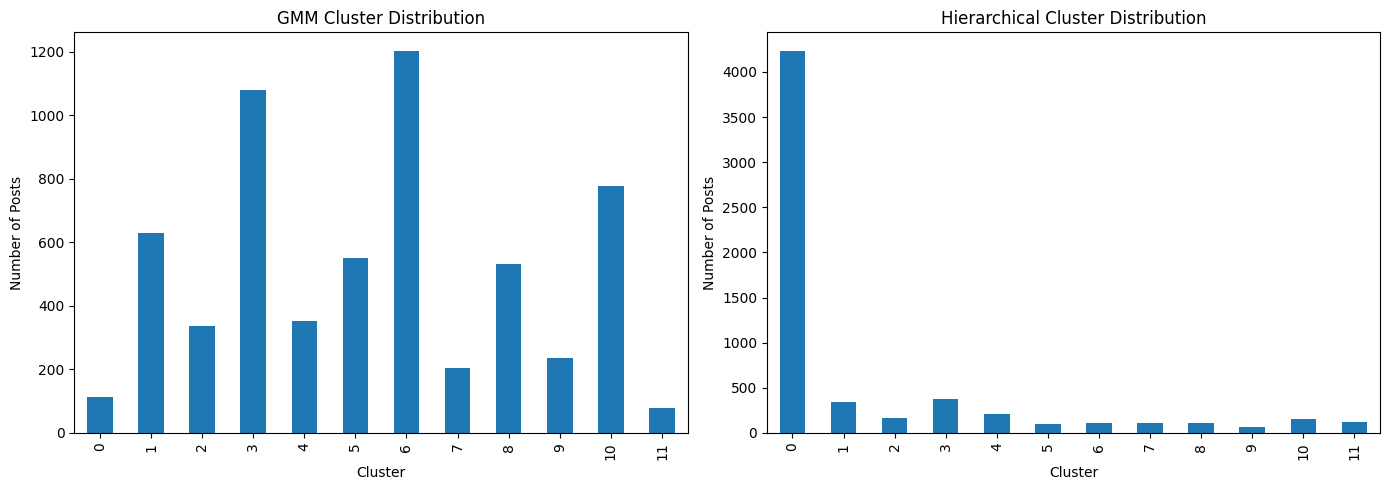

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df['GMM_Cluster_v2'].value_counts().sort_index().plot(
    kind='bar', ax=axes[0]
)
axes[0].set_title('GMM Cluster Distribution')
axes[0].set_xlabel('Cluster')
axes[0].set_ylabel('Number of Posts')

df['Hierarchical_Cluster_v2'].value_counts().sort_index().plot(
    kind='bar', ax=axes[1]
)
axes[1].set_title('Hierarchical Cluster Distribution')
axes[1].set_xlabel('Cluster')
axes[1].set_ylabel('Number of Posts')

plt.tight_layout()
plt.show()

### Cluster Distribution Analysis

The cluster distribution visualization compares the number of social media posts assigned to each cluster by GMM and Hierarchical Clustering. GMM distributes the posts more evenly across the 12 clusters, whereas Hierarchical Clustering assigns approximately 4,200 posts to Cluster 0. This indicates that the two algorithms identify different grouping structures in the dataset. Although GMM provides a more balanced partition, overall clustering quality must be evaluated using internal validation metrics and the interpretability of the discovered topics.

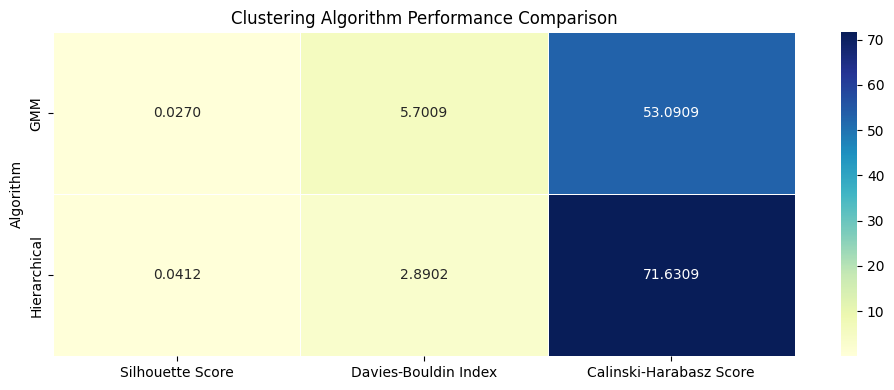

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

metrics = [
    'Silhouette Score',
    'Davies-Bouldin Index',
    'Calinski-Harabasz Score'
]

heatmap_data = final_results_df.set_index('Algorithm')[metrics]

plt.figure(figsize=(10, 4))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.4f',
    cmap='YlGnBu',
    linewidths=0.5
)

plt.title('Clustering Algorithm Performance Comparison')
plt.tight_layout()
plt.show()

This heatmap compares the internal evaluation metrics of GMM and Hierarchical Clustering. Higher Silhouette and Calinski–Harabasz scores are generally preferable, while a lower Davies–Bouldin Index is preferable. Since the metrics have different scales, compare the values within each column rather than comparing colors across different metrics.

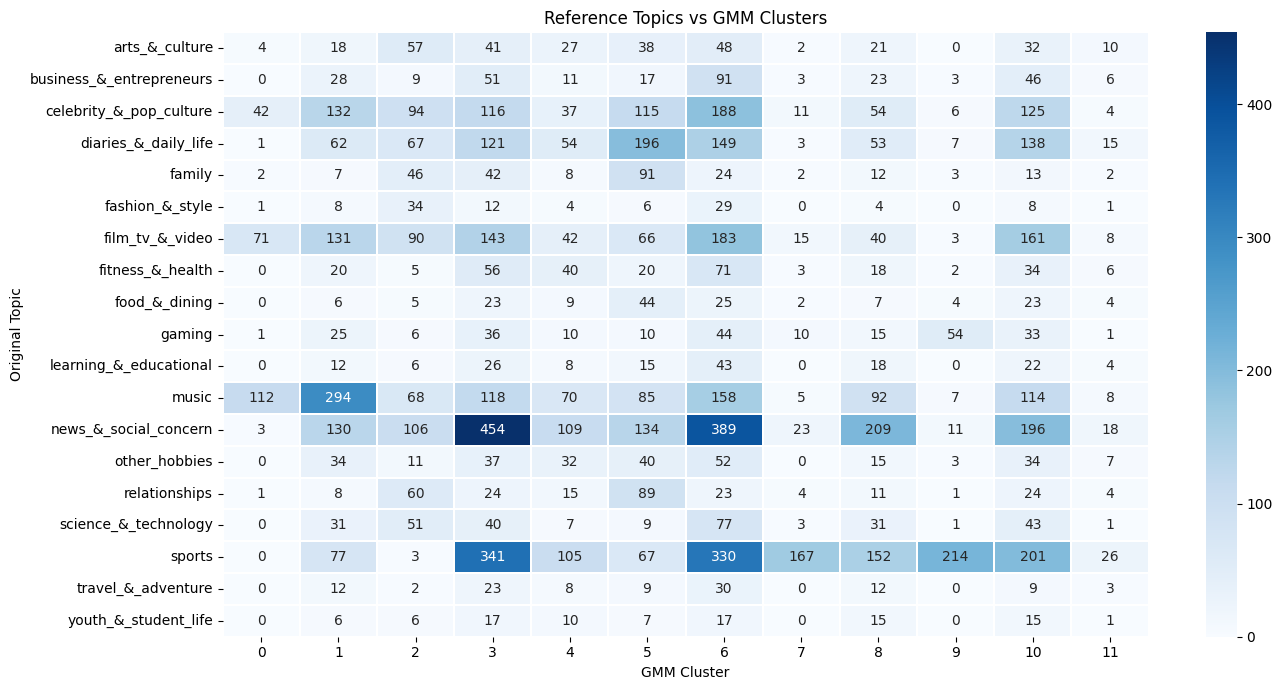

In [41]:
plt.figure(figsize=(14, 7))

sns.heatmap(
    gmm_crosstab,
    annot=True,
    fmt='d',
    cmap='Blues',
    linewidths=0.3
)

plt.title('Reference Topics vs GMM Clusters')
plt.xlabel('GMM Cluster')
plt.ylabel('Original Topic')
plt.tight_layout()
plt.show()

This heatmap compares the original topic categories with the clusters discovered by GMM. Darker cells represent larger counts of topic assignments. It helps identify which clusters are associated with particular topics and which clusters contain mixed topics.

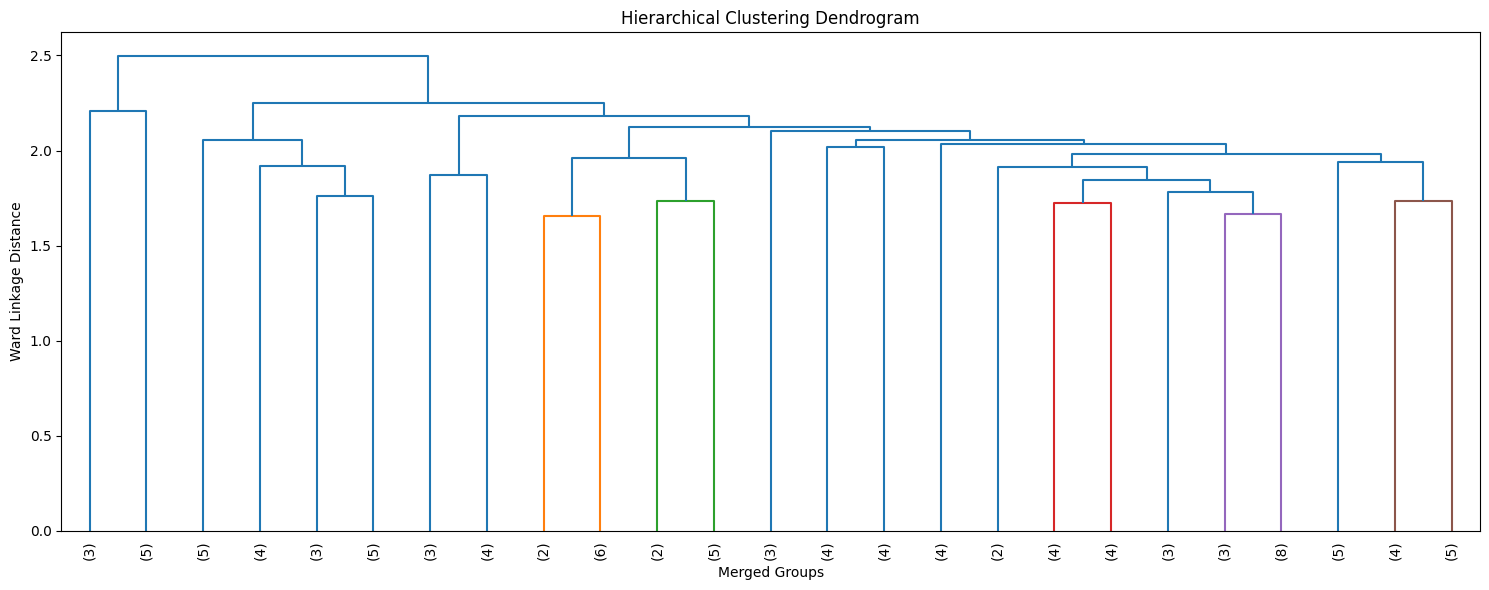

In [42]:
from scipy.cluster.hierarchy import linkage, dendrogram

sample_size = 100
rng = np.random.RandomState(42)

sample_indices = rng.choice(
    len(X_reduced_v2),
    size=sample_size,
    replace=False
)

X_dendrogram = X_reduced_v2[sample_indices]

Z = linkage(
    X_dendrogram,
    method='ward',
    metric='euclidean'
)

plt.figure(figsize=(15, 6))

dendrogram(
    Z,
    truncate_mode='lastp',
    p=25,
    leaf_rotation=90
)

plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Merged Groups')
plt.ylabel('Ward Linkage Distance')
plt.tight_layout()
plt.show()

The dendrogram illustrates the hierarchical merging process. The vertical height of each merge indicates the Ward linkage distance, helping us understand how groups combine at different levels. This is a visualization of a 100-post sample, not the full dataset.